# 02 — Time-specific parking models

Executed on actual September 2025 and August 2026 events. Targets are reconstructed metered sensor panels, not full-curb eligible capacity. No verified unmetered labels or suitable-space probabilities are claimed.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image,display
R=Path('reports/modeling')
manifest=json.loads((R/'label_manifest.json').read_text())
pd.DataFrame(manifest['quality'])

,events,mapped_roster_sensors,roster_faces,all_face_intervals,known_sensor_time_fraction,complete_panel_points,unknown_events,conflicting_event_rows,roster_end_utc,label_start_utc,label_end_utc,month,persistence_minutes
0,245830,313,55,121440,0.059578,881,0,0,2025-09-08T00:00:00-07:00,2025-09-08T00:00:00-07:00,2025-10-01T00:00:00-07:00,2025_09,5
1,245830,313,55,121440,0.136223,2353,0,0,2025-09-08T00:00:00-07:00,2025-09-08T00:00:00-07:00,2025-10-01T00:00:00-07:00,2025_09,15
2,245830,313,55,121440,0.335188,9313,0,0,2025-09-08T00:00:00-07:00,2025-09-08T00:00:00-07:00,2025-10-01T00:00:00-07:00,2025_09,60
3,126313,134,32,73728,0.073802,1050,0,0,2026-08-08T00:00:00-07:00,2026-08-08T00:00:00-07:00,2026-09-01T00:00:00-07:00,2026_08,5
4,126313,134,32,73728,0.169263,2963,0,0,2026-08-08T00:00:00-07:00,2026-08-08T00:00:00-07:00,2026-09-01T00:00:00-07:00,2026_08,15
5,126313,134,32,73728,0.401303,10698,0,0,2026-08-08T00:00:00-07:00,2026-08-08T00:00:00-07:00,2026-09-01T00:00:00-07:00,2026_08,60


## Fixed target and split protocol

15-minute sensor-time bins; 5/15/60-minute cap sensitivity; panels fixed after a seven-day discovery period. Unknown intervals stay unknown. Geometry uses a later snapshot, so even calendar/history experiments remain retrospective.

In [2]:
protocol=json.loads((R/'experiment_protocol.json').read_text())
protocol['config']

{'version': 'sensor-panel-v1',
 'seed': 430,
 'interval_minutes': 15,
 'horizons_minutes': [0, 15, 30, 60, 120],
 'persistence_caps_minutes': [5, 15, 60],
 'primary_persistence_minutes': 15,
 'minimum_known_sensor_time_fraction': 0.25,
 'roster_discovery_days': 7,
 'label_window_minutes': 15,
 'embargo_minutes': 180,
 'rolling_origins_local': ['2026-08-09', '2026-08-13'],
 'rolling_validation_days': 3,
 'final_training_end_local': '2026-08-17',
 'calibration_start_local': '2026-08-18',
 'calibration_end_local': '2026-08-24',
 'final_test_start_local': '2026-08-25',
 'final_test_end_local': '2026-09-01',
 'spatial_holdout_latitude_gte': 34.0635,
 'spatial_buffer_m': 150,
 'prediction_interval_nominal_coverage': 0.9,
 'context_scales_m': [100, 300, 600],
 'hyperparameters': {'ridge_alpha': [1.0, 10.0, 100.0],
  'boosted_max_leaf_nodes': [7, 15]},
 'strict_historical_feature_families': ['calendar', 'causal_sensor_history'],
 'retrospective_feature_families': ['current_spatial_context',
  

In [3]:
metrics=pd.read_csv(R/'metrics.csv')
metrics.query("axis == 'future_time' and target == 'occupancy_rate'")[["horizon","model","n","r2","mae","label_coverage_fraction"]]

,horizon,model,n,r2,mae,label_coverage_fraction
0,0,time_week,6428,0.102411,0.256303,0.299367
1,0,persistence,6428,-0.426746,0.302226,0.299367
2,0,pooled,6428,0.107159,0.258772,0.299367
3,0,regularized,6428,0.204921,0.241796,0.299367
4,0,boosted,6428,0.261529,0.232067,0.299367
40,15,time_week,6425,0.102279,0.256231,0.299674
41,15,persistence,6425,-0.601352,0.322831,0.299674
42,15,pooled,6425,0.106868,0.258665,0.299674
43,15,regularized,6425,0.154279,0.248447,0.299674
44,15,boosted,6425,0.188010,0.242783,0.299674


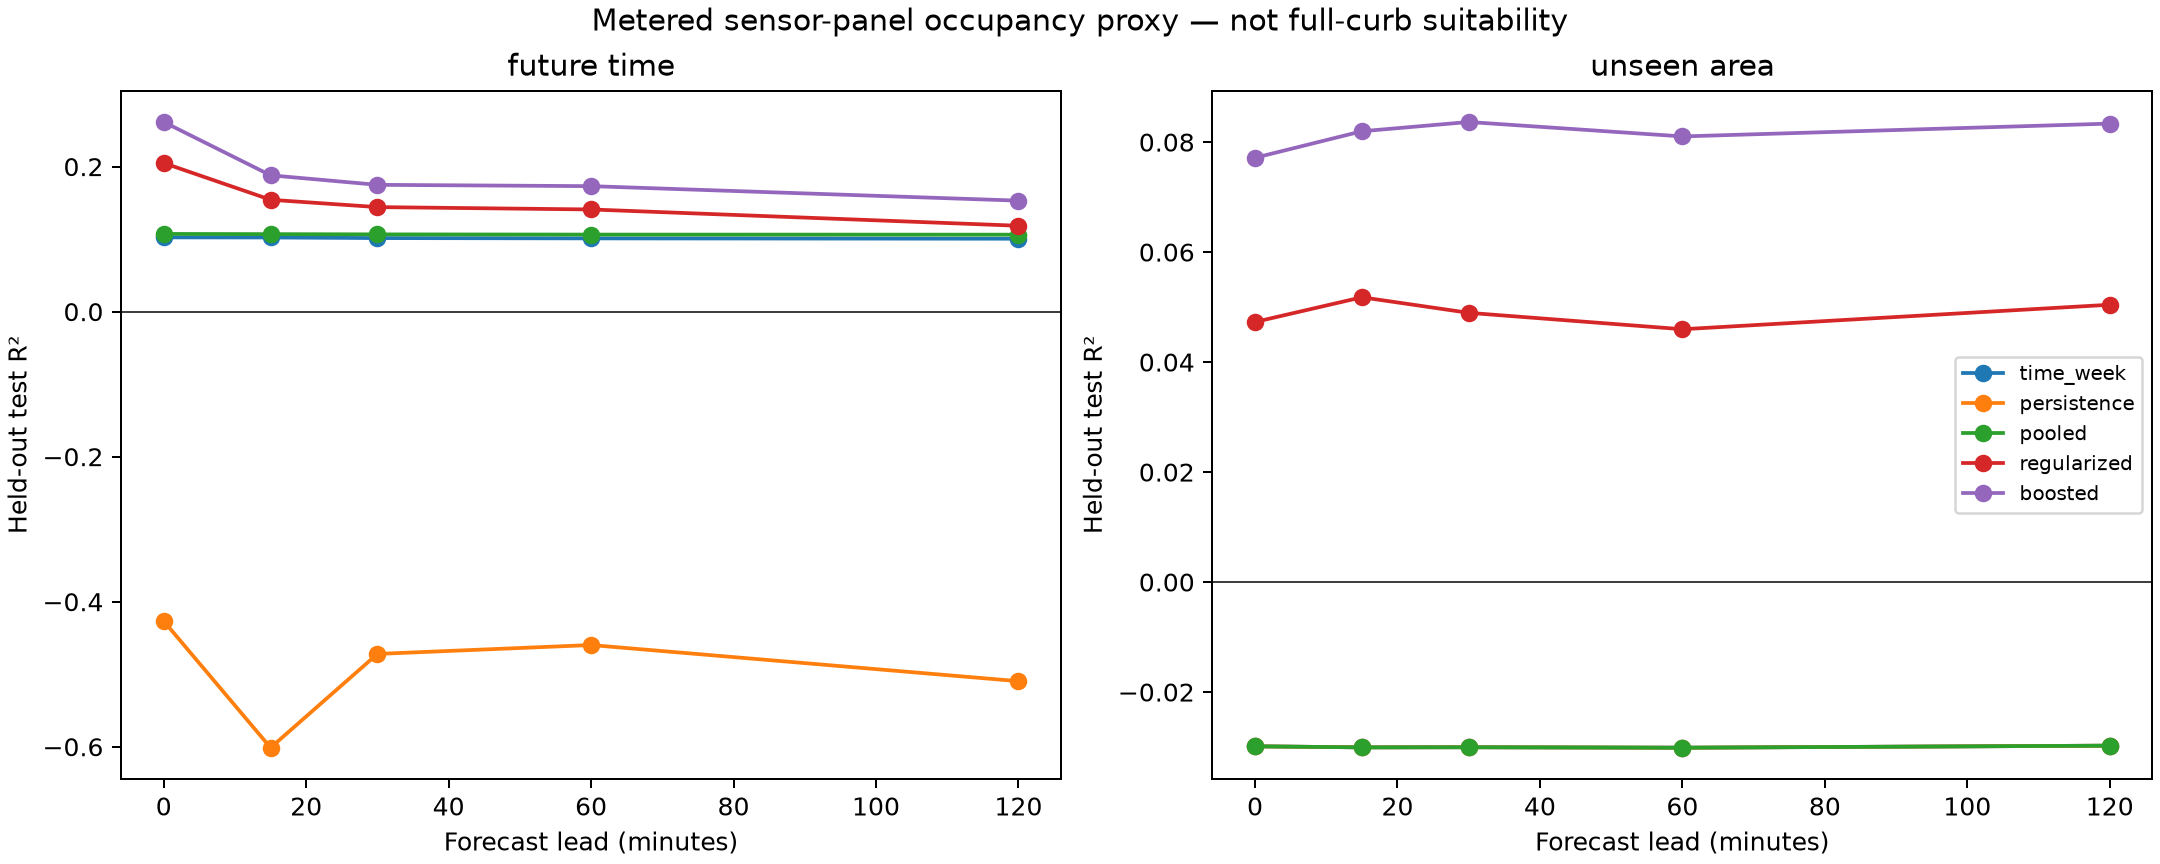

In [4]:
display(Image(filename=str(R/'test_r2.png')))

## Geographic transfer is a separate result

The north area and buffer are withheld. Own-face histories are removed, and neighboring features use training-area sensors only. The pure spatial test overlaps historical time periods; the combined future/unseen-area test is separately named.

In [5]:
metrics.query("axis != 'future_time' and target == 'occupancy_rate' and model == 'boosted'")[["axis","horizon","n","r2","mae"]]

,axis,horizon,n,r2,mae
21,unseen_area,0,3721,0.077147,0.271918
22,future_unseen_area,0,479,-0.083658,0.308843
61,unseen_area,15,3714,0.081971,0.271292
62,future_unseen_area,15,478,-0.065248,0.308056
101,unseen_area,30,3712,0.083654,0.270628
102,future_unseen_area,30,478,-0.067834,0.307999
141,unseen_area,60,3705,0.081029,0.271319
142,future_unseen_area,60,478,-0.061166,0.307088
181,unseen_area,120,3701,0.083361,0.270637
182,future_unseen_area,120,478,-0.057217,0.307005


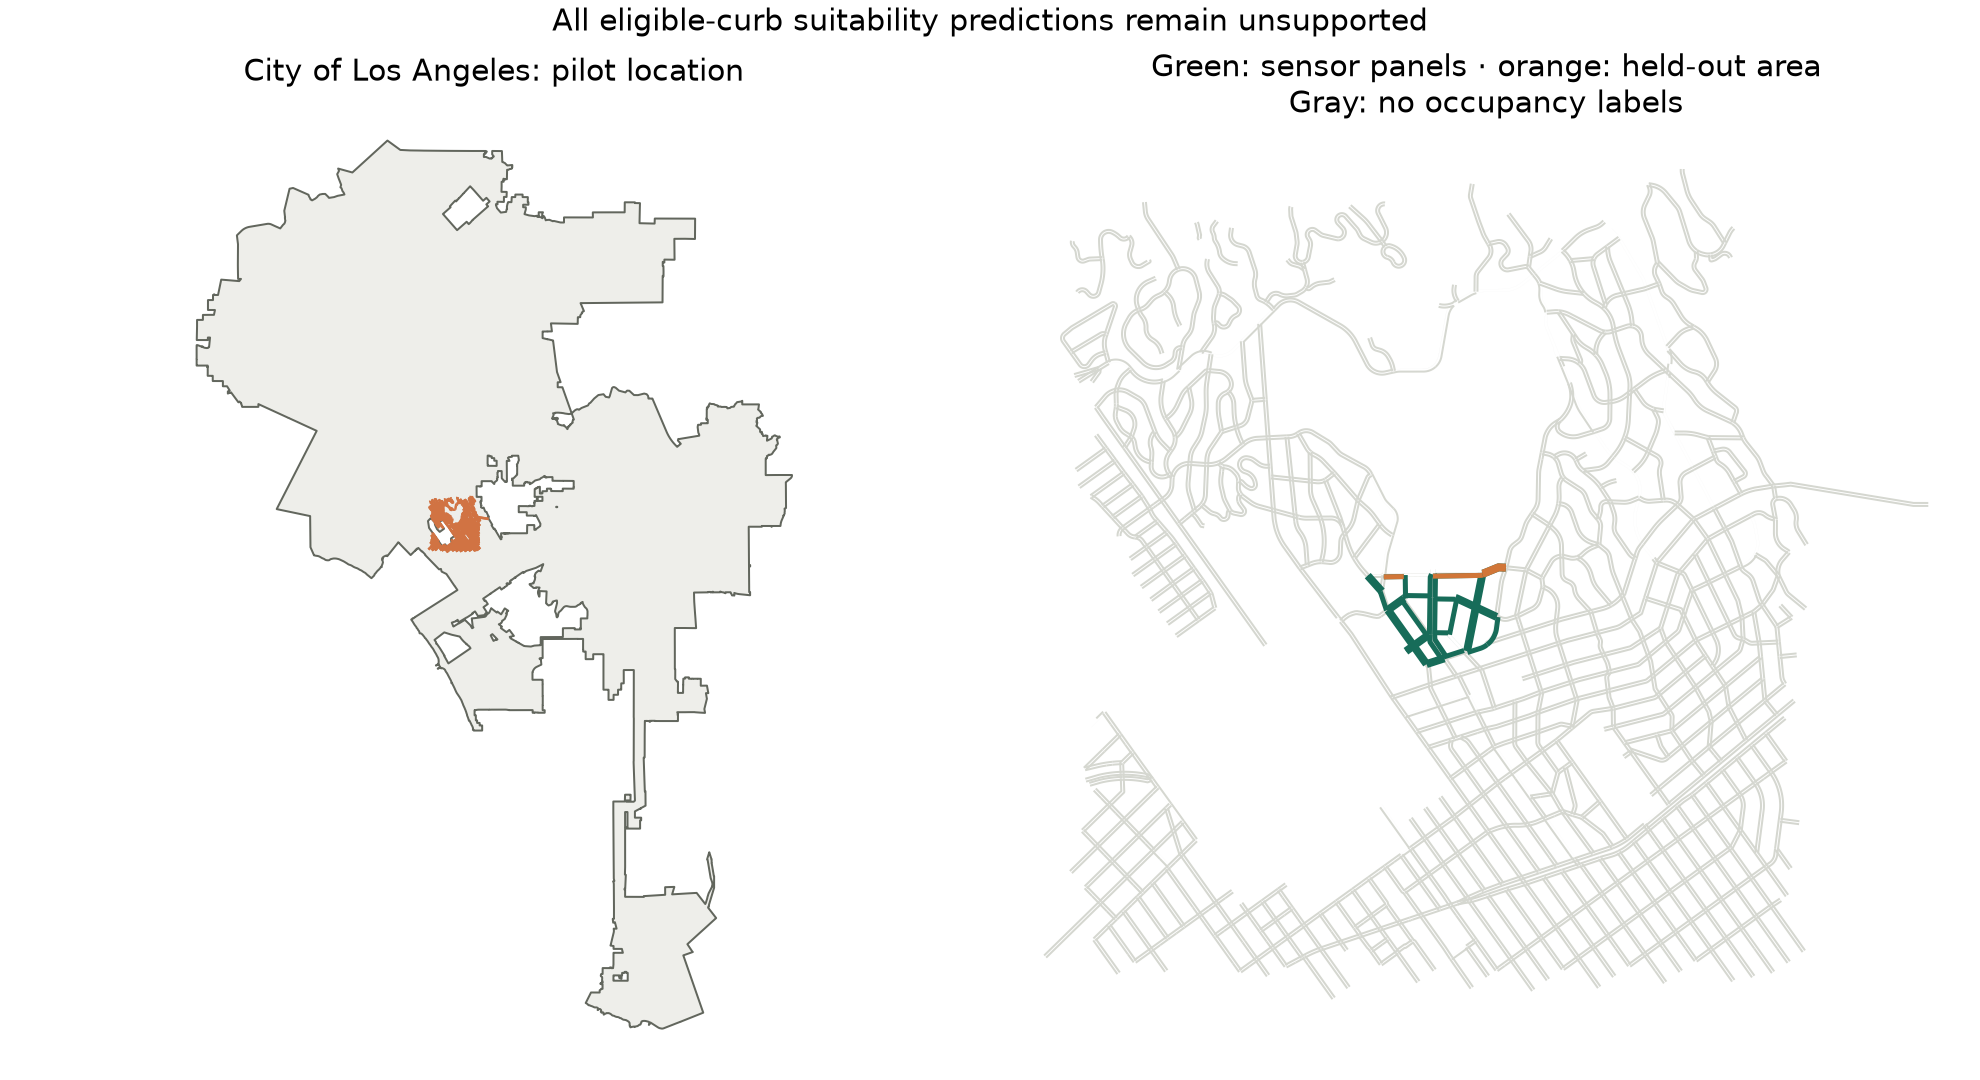

{'city_faces': 162630,
 'faces_with_experimental_panel_labels': 55,
 'faces_without_occupancy_labels': 162575,
 'validated_suitable_space_faces': 0,
 'unmetered_test_labels': 0,
 'citywide_numerical_suitability_abstention_rate': 1.0}

In [6]:
display(Image(filename=str(R/'coverage.png')))
json.loads((R/'geographic_support.json').read_text())

## Counts, binary panel outcomes and uncertainty

Counts require a complete sensor panel at the point time. A directly fitted binary panel-vacancy outcome avoids space-independence assumptions. It is not a verified legal-suitability label. Calibration and residual ranges use a separate earlier period, with empirical held-out coverage reported.

In [7]:
metrics.query("axis == 'future_time' and model == 'boosted' and target != 'occupancy_rate'")[["target","horizon","n","mae","r2","brier_score","log_loss","interval_coverage","interval_mean_width"]]

,target,horizon,n,mae,r2,brier_score,log_loss,interval_coverage,interval_mean_width
9,available_count,0,839,0.271095,0.668421,NaN,NaN,0.908224,1.016168
13,any_panel_vacant,0,839,NaN,NaN,0.083801,0.273005,NaN,NaN
49,available_count,15,839,0.505345,0.297885,NaN,NaN,0.907032,1.229053
53,any_panel_vacant,15,839,NaN,NaN,0.203943,0.595893,NaN,NaN
89,available_count,30,838,0.519330,0.259501,NaN,NaN,0.909308,1.250774
93,any_panel_vacant,30,838,NaN,NaN,0.209848,0.609176,NaN,NaN
129,available_count,60,838,0.519498,0.255501,NaN,NaN,0.906921,1.236545
133,any_panel_vacant,60,838,NaN,NaN,0.211127,0.611534,NaN,NaN
169,available_count,120,836,0.529468,0.224617,NaN,NaN,0.899522,1.250054
173,any_panel_vacant,120,836,NaN,NaN,0.213041,0.617161,NaN,NaN


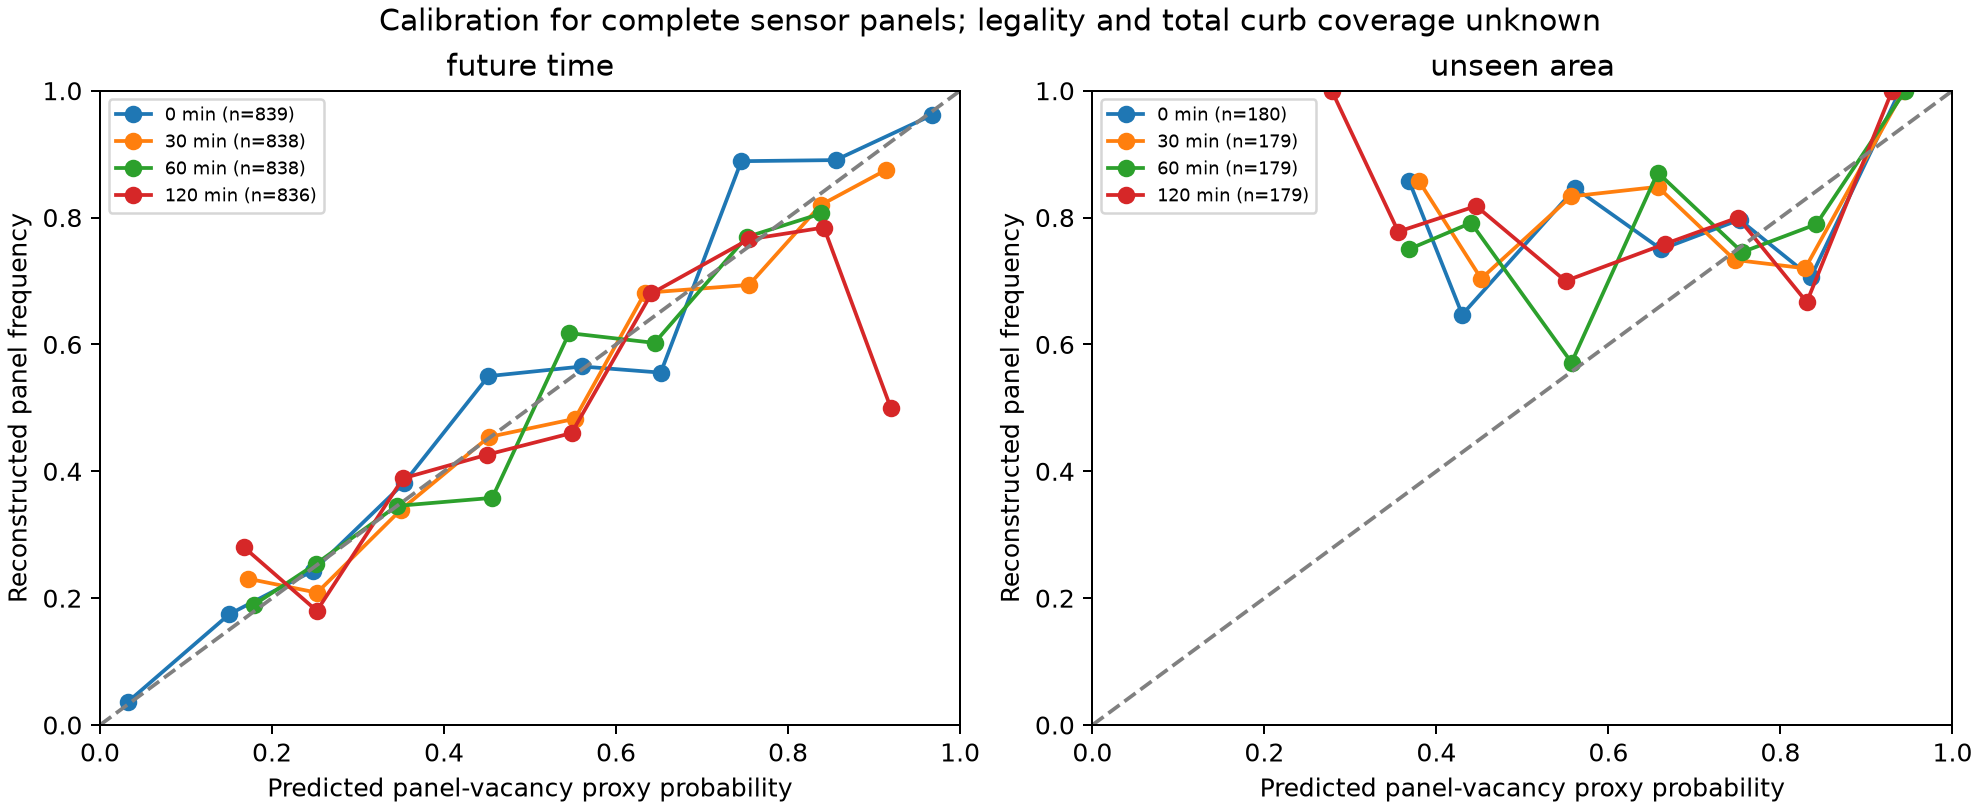

In [8]:
display(Image(filename=str(R/'calibration.png')))

In [9]:
pd.read_json(R/'ablations.json')[["axis","horizon","family_variant","r2","mae"]]

,axis,horizon,family_variant,r2,mae
0,future_time,0,calendar_only,0.123410,0.253076
1,future_time,0,no_neighbors,0.264464,0.231222
2,future_time,0,retrospective_context,0.277651,0.228046
3,unseen_area,0,calendar_only,0.074251,0.271284
4,unseen_area,0,no_neighbors,0.074251,0.271284
5,unseen_area,0,retrospective_context,0.059921,0.273064
6,future_time,15,calendar_only,0.122219,0.253036
7,future_time,15,no_neighbors,0.191905,0.241542
8,future_time,15,retrospective_context,0.228819,0.234109
9,unseen_area,15,calendar_only,0.075835,0.270924


In [10]:
pd.read_json(R/'persistence_sensitivity.json')

,horizon_minutes,persistence_minutes,scope,n,r2,mae,rmse,r2_note
0,0,5,"common labeled test rows; fixed primary model,...",1991,-0.033537,0.205295,0.259417,NaN
1,0,15,"common labeled test rows; fixed primary model,...",1991,0.129963,0.207336,0.259785,NaN
2,0,60,"common labeled test rows; fixed primary model,...",1991,0.225670,0.194306,0.243830,NaN
3,15,5,"common labeled test rows; fixed primary model,...",1990,-0.031373,0.203581,0.258902,NaN
4,15,15,"common labeled test rows; fixed primary model,...",1990,0.094001,0.209315,0.264874,NaN
5,15,60,"common labeled test rows; fixed primary model,...",1990,0.182894,0.197755,0.250458,NaN
6,30,5,"common labeled test rows; fixed primary model,...",1990,-0.045898,0.205413,0.260718,NaN
7,30,15,"common labeled test rows; fixed primary model,...",1990,0.082945,0.209123,0.266486,NaN
8,30,60,"common labeled test rows; fixed primary model,...",1990,0.175230,0.197270,0.251629,NaN
9,60,5,"common labeled test rows; fixed primary model,...",1990,-0.056383,0.205585,0.262022,NaN


## Forecast contracts and unsupported fields

All eligible-capacity, suitable-space probability and eligible net-change fields remain null. Sensor diagnostics and experimental activity ranks are isolated and labelled. Typical-pattern requests use no recent-state information.

In [11]:
examples=[json.loads(s) for s in (R/'forecast_examples.jsonl').read_text().splitlines()]
assert all(r['probability_at_least_one'] is None and r['expected_available_spaces'] is None for r in examples)
pd.DataFrame(examples)[['forecast_mode','support','horizon_minutes','unavailable_reason']].value_counts()

forecast_mode          support                       horizon_minutes  unavailable_reason                                                                                                               
typical_pattern        experimental_sensor_panel     10080            Sensor diagnostics only: unknown total capacity, incomplete curb coverage, unverified historical geometry and full-duration rules    12
insufficient_data      insufficient_data             15               Latest mapped transaction or recent sensor-time features exceed the freshness policy                                                 10
                                                     30               Latest mapped transaction or recent sensor-time features exceed the freshness policy                                                 10
                                                     0                Latest mapped transaction or recent sensor-time features exceed the freshness policy                            

In [12]:
json.loads((R/'validation.json').read_text())

{'source_fingerprint_matched': True,
 'event_feature_asof_checks_passed': True,
 'historical_geometry_verified': False,
 'event_delivery_latency_verified': False,
 'retrospective_only': True,
 'spatial_overlap_blocks': 0,
 'full_curb_labels': 0,
 'model_files': 122,
 'forecast_examples': 74,
 'user_facing_suitability_values': 0,
 'population': 'metered sensor panels only',
 'unmetered_test_r2': None,
 'rate_results_unchanged_after_count_correction': True}

## Decision

This run supports reproducible experimental diagnostics on metered sensor panels. It does not establish unmetered, legal-duration or citywide accuracy. Independent randomized/repeated surveys, historical source alignment, and verified capacity/rules are needed before exposing numerical user predictions. The aspirational 0.50 unmetered test R² is not evaluated here.